# 01. Dataset Acquisition, Schema Validation & Exploratory Data Analysis (EDA)

**Author:** Member 1 (Shreyas)  
**Role:** Data Acquisition, Data Quality, Schema Validation, and EDA  
**Project:** AI-Based Technical Skill Development Assistant  
**Artifact:** Phase 1 Bootstrap Interaction Telemetry (`data/raw/student_interactions_bootstrap.csv`)  

---

## Executive Summary
This notebook documents the acquisition, data quality validation, and exploratory data analysis of the Phase 1 interaction telemetry dataset. In accordance with project requirements:
1. All learning interaction events reflect structured user actions (confidence assessment, revision, quizzes, answers).
2. The dataset is explicitly designated as **Synthetic Bootstrap Data** (`is_synthetic = True`) to resolve the cold-start problem before real students log into the platform.
3. We perform rigorous schema validation, check for nulls and duplicate keys, analyze distributions of self-reported confidence against demonstrated quiz outcomes, and examine calibration gaps (overconfidence vs. underconfidence).


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Add project root to sys.path for local imports
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.data_validation import DataQualityValidator, LearningInteractionEvent, EventType

# Set styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print("Packages successfully imported.")


Packages successfully imported.


## 1. Dataset Loading & High-Level Inspection

In [2]:
data_path = os.path.join(project_root, "data", "raw", "student_interactions_bootstrap.csv")
assert os.path.exists(data_path), f"Dataset not found at {data_path}"

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Total Unique Students: {df['student_id'].nunique()}")
print(f"Total Unique Topics: {df['topic_id'].nunique()}")
print(f"Synthetic Data Ratio: {df['is_synthetic'].mean() * 100:.1f}%")
df.head(10)


Dataset Shape: 2721 rows, 15 columns
Total Unique Students: 50
Total Unique Topics: 6
Synthetic Data Ratio: 100.0%


,event_id,timestamp,student_id,topic_id,event_type,attempt_id,question_id,confidence_score,selected_option,is_correct,response_time_seconds,quiz_score,revision_status,readiness_status,is_synthetic
0,ev_9b4e9949ec58,2026-10-04T12:08:00Z,std_sim_001,topic_superv_01,topic_selected,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,ev_cb4b8f095985,2026-10-04T12:08:36Z,std_sim_001,topic_superv_01,confidence_assessment_submitted,NaN,NaN,67.0,NaN,NaN,NaN,NaN,NaN,NaN,True
2,ev_894f9e1e0670,2026-10-04T12:09:28Z,std_sim_001,topic_superv_01,quiz_started,att_001_v_01_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
3,ev_6b1eb2f2833f,2026-10-04T12:09:43Z,std_sim_001,topic_superv_01,question_answered,att_001_v_01_1,q_erv_01_01,NaN,B,True,13.6,NaN,NaN,NaN,True
4,ev_a14876239a9a,2026-10-04T12:10:28Z,std_sim_001,topic_superv_01,question_answered,att_001_v_01_1,q_erv_01_02,NaN,B,True,43.9,NaN,NaN,NaN,True
5,ev_9dffb191555f,2026-10-04T12:11:19Z,std_sim_001,topic_superv_01,question_answered,att_001_v_01_1,q_erv_01_03,NaN,A,False,49.2,NaN,NaN,NaN,True
6,ev_8df27e039948,2026-10-04T12:11:47Z,std_sim_001,topic_superv_01,question_answered,att_001_v_01_1,q_erv_01_04,NaN,A,True,26.7,NaN,NaN,NaN,True
7,ev_e34ba2b44ae4,2026-10-04T12:12:09Z,std_sim_001,topic_superv_01,question_answered,att_001_v_01_1,q_erv_01_05,NaN,B,False,20.5,NaN,NaN,NaN,True
8,ev_9b2dee7aad50,2026-10-04T12:12:18Z,std_sim_001,topic_superv_01,quiz_submitted,att_001_v_01_1,NaN,NaN,NaN,NaN,NaN,60.0,NaN,NaN,True
9,ev_8eee1cecae43,2026-10-04T12:12:18Z,std_sim_001,topic_superv_01,quiz_result_calculated,att_001_v_01_1,NaN,NaN,NaN,NaN,NaN,60.0,NaN,Developing,True


## 2. Automated Schema Validation & Data Quality Audit
We execute `DataQualityValidator.validate_dataframe(df)` to verify:
- Presence of all mandatory schema columns.
- Zero duplicate `event_id` occurrences.
- Numerical bounds verification ($C \in [0, 100]$, $S \in [0, 100]$, $t \ge 0$).
- Event type registry verification.


In [3]:
report = DataQualityValidator.validate_dataframe(df)

print(f"Validation Status: {report.validation_status}")
print(f"Duplicate Event IDs: {report.duplicate_event_ids}")
print(f"Invalid Range Violations: {report.invalid_range_counts}")
print(f"Unique Students: {report.unique_students}")
print(f"Unique Topics: {report.unique_topics}")
print("\nIssues / Notes Detected:")
for issue in report.issues_detected:
    print(f" - {issue}")


Validation Status: WARNING
Duplicate Event IDs: 0
Invalid Range Violations: {'confidence_score': 0, 'quiz_score': 0, 'response_time_seconds': 0}
Unique Students: 50
Unique Topics: 6

Issues / Notes Detected:
 - Note: Dataset contains 100.0% synthetic bootstrap records.


## 3. Missing Value & Nullability Audit
Because the dataset is a sparse event stream across distinct event types, optional fields are expected to be null for unrelated events (e.g., `confidence_score` is only present for confidence events; `selected_option` is only present for answer events).


In [4]:
missing_df = pd.DataFrame({
    "Null Count": df.isna().sum(),
    "Null Percentage": (df.isna().sum() / len(df)) * 100
})
print("Missing Value Breakdown across Event Stream:")
missing_df


Missing Value Breakdown across Event Stream:


,Null Count,Null Percentage
event_id,0,0.000000
timestamp,0,0.000000
student_id,0,0.000000
topic_id,0,0.000000
event_type,0,0.000000
attempt_id,606,22.271224
question_id,1546,56.817347
confidence_score,2550,93.715546
selected_option,1546,56.817347
is_correct,1546,56.817347


## 4. Interaction Event Type Distribution

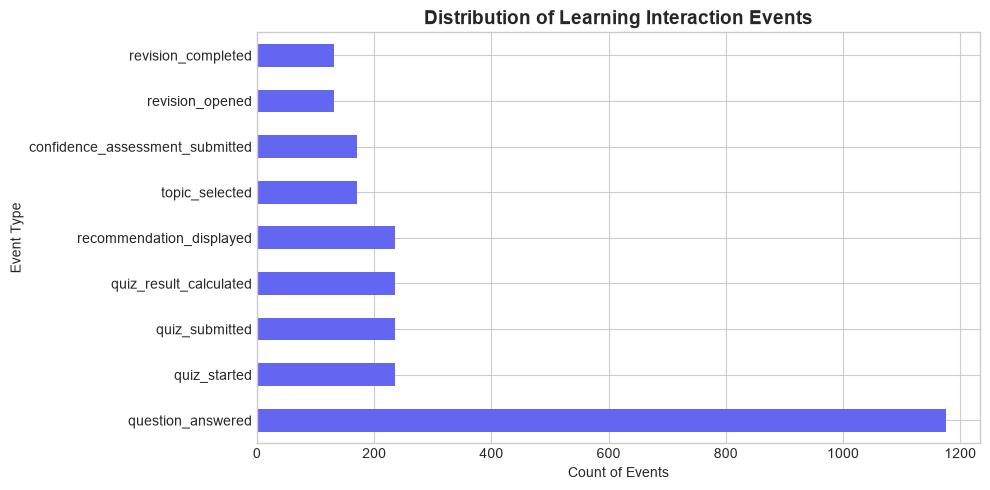

event_type
question_answered                  1175
quiz_started                        235
quiz_submitted                      235
quiz_result_calculated              235
recommendation_displayed            235
topic_selected                      171
confidence_assessment_submitted     171
revision_opened                     132
revision_completed                  132
Name: count, dtype: int64


In [5]:
event_counts = df['event_type'].value_counts()

plt.figure(figsize=(10, 5))
event_counts.plot(kind='barh', color='#6366f1')
plt.title("Distribution of Learning Interaction Events", fontsize=14, fontweight='bold')
plt.xlabel("Count of Events")
plt.ylabel("Event Type")
plt.tight_layout()
plt.show()

print(event_counts)


## 5. Analysis of Self-Reported Confidence
We analyze the distribution of confidence ratings submitted by students across topics.
The application applies a threshold of **60%**: topics below this threshold trigger recommended revision and interactive flashcards.


Total Confidence Assessments: 171
Mean Confidence: 50.82%
Median Confidence: 49.90%
Std Dev: 19.97
Low Confidence (< 60%): 116 (67.8%)


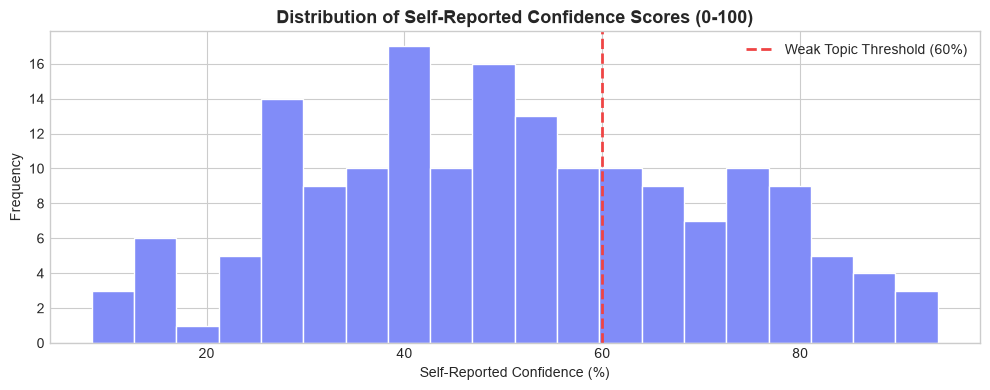

In [6]:
conf_events = df[df['event_type'] == 'confidence_assessment_submitted'].dropna(subset=['confidence_score'])

print(f"Total Confidence Assessments: {len(conf_events)}")
print(f"Mean Confidence: {conf_events['confidence_score'].mean():.2f}%")
print(f"Median Confidence: {conf_events['confidence_score'].median():.2f}%")
print(f"Std Dev: {conf_events['confidence_score'].std():.2f}")
print(f"Low Confidence (< 60%): {(conf_events['confidence_score'] < 60).sum()} ({(conf_events['confidence_score'] < 60).mean()*100:.1f}%)")

plt.figure(figsize=(10, 4))
plt.hist(conf_events['confidence_score'], bins=20, color='#818cf8', edgecolor='white')
plt.axvline(60, color='#ef4444', linestyle='--', linewidth=2, label='Weak Topic Threshold (60%)')
plt.title("Distribution of Self-Reported Confidence Scores (0-100)", fontsize=13, fontweight='bold')
plt.xlabel("Self-Reported Confidence (%)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Self-Reported Confidence vs. Demonstrated Quiz Mastery
**Essential Scientific Distinction:** Self-reported confidence is not equivalent to demonstrated competence.
Here, we pair each student's pre-quiz confidence score with their subsequently demonstrated quiz score on that same topic.


In [7]:
# Extract paired confidence and quiz results
conf_df = df[df['event_type'] == 'confidence_assessment_submitted'][['student_id', 'topic_id', 'confidence_score']].dropna()
quiz_df = df[df['event_type'] == 'quiz_result_calculated'][['student_id', 'topic_id', 'quiz_score', 'readiness_status']].dropna()

paired = pd.merge(conf_df, quiz_df, on=['student_id', 'topic_id'])
paired['gap'] = paired['confidence_score'] - paired['quiz_score']

# Categorize calibration
def categorize_gap(gap):
    if gap > 20:
        return 'Overconfident (Gap > +20%)'
    elif gap < -20:
        return 'Underconfident (Gap < -20%)'
    else:
        return 'Well-Calibrated'

paired['calibration'] = paired['gap'].apply(categorize_gap)

print(f"Paired Assessments: {len(paired)}")
corr = paired['confidence_score'].corr(paired['quiz_score'])
print(f"Pearson Correlation (Confidence vs Quiz Score): {corr:.4f}")
print("\nCalibration Breakdown:")
print(paired['calibration'].value_counts(normalize=True) * 100)


Paired Assessments: 235
Pearson Correlation (Confidence vs Quiz Score): 0.2511

Calibration Breakdown:
calibration
Well-Calibrated                48.510638
Underconfident (Gap < -20%)    37.446809
Overconfident (Gap > +20%)     14.042553
Name: proportion, dtype: float64


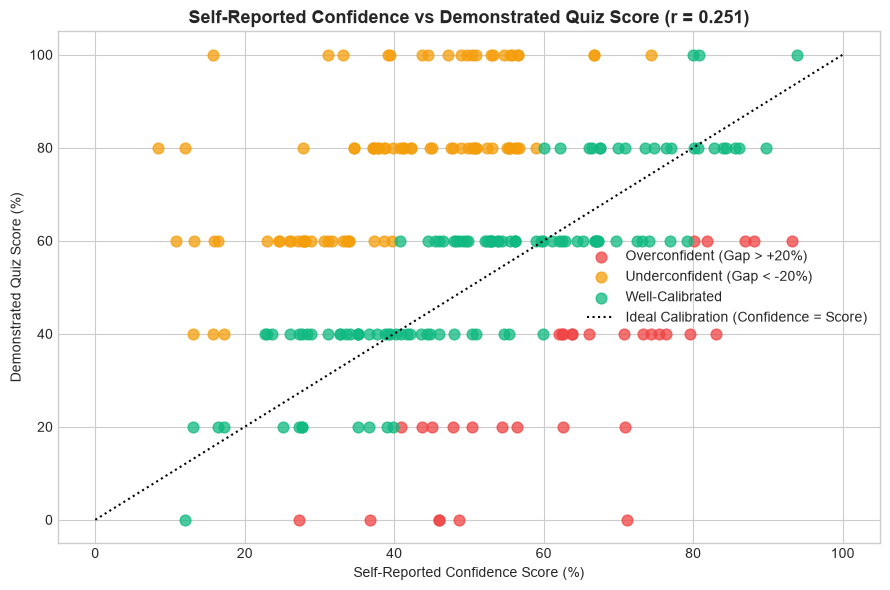

In [8]:
plt.figure(figsize=(9, 6))
colors = {'Overconfident (Gap > +20%)': '#ef4444', 'Well-Calibrated': '#10b981', 'Underconfident (Gap < -20%)': '#f59e0b'}

for label, group in paired.groupby('calibration'):
    plt.scatter(group['confidence_score'], group['quiz_score'], label=label, color=colors.get(label, 'grey'), alpha=0.75, s=60)

# Ideal calibration diagonal line
plt.plot([0, 100], [0, 100], color='black', linestyle=':', label='Ideal Calibration (Confidence = Score)')
plt.title(f"Self-Reported Confidence vs Demonstrated Quiz Score (r = {corr:.3f})", fontsize=13, fontweight='bold')
plt.xlabel("Self-Reported Confidence Score (%)")
plt.ylabel("Demonstrated Quiz Score (%)")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Topic-Wise Demonstrated Performance Breakdown

In [9]:
topic_summary = paired.groupby('topic_id').agg(
    mean_confidence=('confidence_score', 'mean'),
    mean_quiz_score=('quiz_score', 'mean'),
    attempt_count=('quiz_score', 'count'),
    mean_gap=('gap', 'mean')
).round(2)

print("Topic-Wise Mean Metrics:")
topic_summary


Topic-Wise Mean Metrics:


,mean_confidence,mean_quiz_score,attempt_count,mean_gap
topic_id,,,,
topic_bias_var_02,52.22,62.42,33,-10.21
topic_dvc_version_01,44.60,64.23,52,-19.63
topic_eval_metrics_03,50.64,49.00,40,1.64
topic_mlflow_track_02,55.14,65.16,31,-10.02
topic_superv_01,49.94,62.35,34,-12.41
topic_tree_ensembles_04,46.22,56.00,45,-9.78


## 8. Dataset Limitations & Phase 1 Conclusions

1. **Synthetic Nature**: All records are generated from a documented stochastic simulation. While the statistical properties reflect realistic educational dynamics (including calibration bias and Dunning-Kruger effects), they do not represent real human observations.
2. **Pedagogical Claims**: High model accuracy or correlation metrics obtained on this dataset validate **pipeline correctness**, not real-world pedagogical outcomes.
3. **Transition to Production**: As genuine learners interact with the platform, the telemetry service logs real interaction events into SQLite / CSV event stores, which will be versioned under DVC in future project iterations.
